# From the Schrödinger equation to full CI

**Marcus Center Winter School 2026 · Ab initio quantum chemistry · PySCF exercise, notebook 0**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Caltech-Marcus-Center/Winter-School/blob/main/2026/01_ab_initio_quantum_chemistry/00_schrodinger_to_fci.ipynb)

Almost every quantum chemistry method is linear algebra on two arrays of numbers: the one-electron
integrals $h_{pq}$ and the two-electron integrals $(pq|rs)$. This notebook builds that picture from the
ground up, writing each step by hand in NumPy and checking it against PySCF.

| Section | Idea | What we code |
| --- | --- | --- |
| 1 | A finite basis turns the Schrödinger equation into a matrix problem | the hydrogen atom in Gaussians |
| 2 | Atom-centred Gaussians: local, and integrable in closed form | the Gaussian product theorem; integrals from PySCF |
| 3 | The whole problem is $h_{pq}$ and $(pq|rs)$ | Hartree–Fock in 15 lines |
| 4 | Exact diagonalisation in Fock space | Jordan–Wigner matrices for H₄ |
| 5 | Full CI for larger systems: never build $H$ | a direct-CI $\sigma = HC$ routine |
| 6 | Everything else is an approximation to Section 5 | MP2 in 5 lines |

By the end you should be able to write a working version of most quantum chemistry methods yourself,
given a paper with the equations.

Everything runs in well under a minute. Atomic units throughout: energies in Hartree, lengths in Bohr
unless stated.

In [1]:
# On Google Colab, uncomment the next line.
# !pip install -q pyscf matplotlib

import itertools
import time
from math import comb

import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg
import scipy.sparse as sp
import scipy.sparse.linalg
from pyscf import cc, fci, gto, mp, scf

np.set_printoptions(precision=5, suppress=True, linewidth=120)
INK, MUTED, BLUE, ORANGE, AQUA = "#191919", "#666666", "#257de0", "#f47230", "#00b894"

## 1. A finite basis turns the Schrödinger equation into a matrix problem

Take the simplest case, the hydrogen atom:

$$\hat H\psi = E\psi, \qquad \hat H = -\tfrac12\nabla^2 - \frac{1}{r}.$$

Expand the unknown wavefunction in $n$ fixed functions, $\psi(\mathbf r) = \sum_\mu c_\mu\,\chi_\mu(\mathbf r)$,
and minimise the energy over the coefficients. The result is a **generalised eigenvalue problem**

$$\mathbf H\mathbf c = E\,\mathbf S\mathbf c, \qquad
H_{\mu\nu} = \langle\chi_\mu|\hat H|\chi_\nu\rangle, \quad S_{\mu\nu} = \langle\chi_\mu|\chi_\nu\rangle .$$

The overlap matrix $\mathbf S$ appears because the basis functions need not be orthogonal. Two facts make
this useful:

- **It is variational.** The lowest eigenvalue is an upper bound to the exact energy.
- **It converges.** Adding functions can only lower it.

For basis functions we use Gaussians $\chi_\mu = e^{-\alpha_\mu r^2}$. Every matrix element is then a
closed formula:

$$S_{\mu\nu} = \Big(\frac{\pi}{\alpha_\mu+\alpha_\nu}\Big)^{3/2},\qquad
T_{\mu\nu} = \frac{3\,\alpha_\mu\alpha_\nu}{\alpha_\mu+\alpha_\nu}\,S_{\mu\nu},\qquad
V_{\mu\nu} = -\frac{2\pi}{\alpha_\mu+\alpha_\nu}.$$

In [2]:
def hydrogen_in_gaussians(alphas):
    """Ground state of the H atom in s-type Gaussians exp(-alpha r^2). Returns energy, coefficients."""
    a = np.asarray(alphas, dtype=float)
    p = a[:, None] + a[None, :]
    S = (np.pi / p) ** 1.5
    T = 3 * a[:, None] * a[None, :] / p * S
    V = -2 * np.pi / p
    energies, coeffs = scipy.linalg.eigh(T + V, S)     # solves H c = E S c
    return energies[0], coeffs[:, 0]


def even_tempered(n, centre=0.5, ratio=3.5):
    """n exponents in a geometric series centred on `centre`."""
    return centre * ratio ** (np.arange(n) - (n - 1) / 2)


print("  n   energy (Ha)   error (Ha)")
for n in [1, 2, 3, 4, 6, 8, 12]:
    e, _ = hydrogen_in_gaussians(even_tempered(n))
    print(f" {n:2d}   {e:.8f}   {e + 0.5:.1e}")
print("exact  -0.50000000")

  n   energy (Ha)   error (Ha)
  1   -0.37837917   1.2e-01
  2   -0.46396807   3.6e-02
  3   -0.49233028   7.7e-03
  4   -0.49678637   3.2e-03
  6   -0.49936421   6.4e-04
  8   -0.49980585   1.9e-04
 12   -0.49988976   1.1e-04
exact  -0.50000000


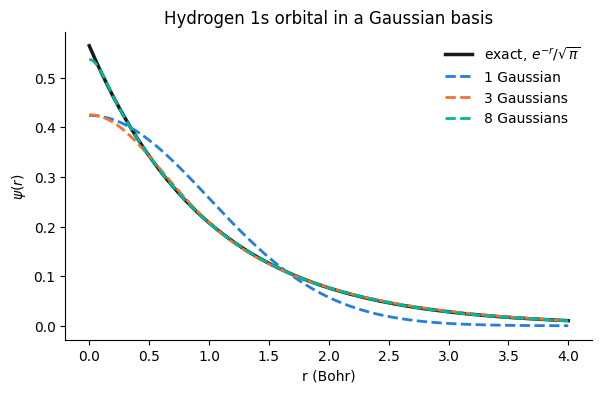

In [3]:
r = np.linspace(0, 4, 400)
fig, ax = plt.subplots(figsize=(6.8, 4))
ax.plot(r, np.exp(-r) / np.sqrt(np.pi), color=INK, lw=2.5, label="exact, $e^{-r}/\\sqrt{\\pi}$")
for n, colour in [(1, BLUE), (3, ORANGE), (8, AQUA)]:
    alphas = even_tempered(n)
    _, c = hydrogen_in_gaussians(alphas)
    psi = np.abs(np.exp(-np.outer(r**2, alphas)) @ c)
    ax.plot(r, psi, color=colour, lw=2, ls="--", label=f"{n} Gaussian{'s' if n > 1 else ''}")
ax.set(xlabel="r (Bohr)", ylabel="$\\psi(r)$", title="Hydrogen 1s orbital in a Gaussian basis")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False);

**What to notice.** The energy converges from above, quickly at first; it then stalls near $10^{-4}$ Ha,
a limit set by how widely the exponents are spaced (Exercise 1). The wavefunction is good everywhere except
at the nucleus, where the exact solution has a cusp and a Gaussian is flat. A single Gaussian is a poor
atomic orbital; a fixed combination of a few is a good one. That is all a "basis set" is: a table of
exponents and contraction coefficients per element, fitted once and reused.

## 2. Atom-centred Gaussians

**Why centre the functions on atoms?** A molecule's wavefunction looks, to a first approximation, like
atomic orbitals glued together. A handful of functions per atom already gives a qualitatively right
answer, the number of functions grows linearly with the number of atoms, and distant functions do not
overlap, which makes the matrices sparse for large systems. A uniform grid or plane-wave basis for a
water molecule needs $10^4$–$10^6$ functions; a minimal atomic basis needs 7.

**Why Gaussians, when exponentials $e^{-\zeta r}$ have the right shape?** Because of one identity, the
**Gaussian product theorem**: the product of two Gaussians on different centres is a single Gaussian on
a point in between,

$$e^{-\alpha|\mathbf r-\mathbf A|^2}\,e^{-\beta|\mathbf r-\mathbf B|^2}
 = e^{-\frac{\alpha\beta}{\alpha+\beta}|\mathbf A-\mathbf B|^2}\;e^{-(\alpha+\beta)|\mathbf r-\mathbf P|^2},
 \qquad \mathbf P = \frac{\alpha\mathbf A+\beta\mathbf B}{\alpha+\beta}.$$

A four-centre integral over $\chi_\mu\chi_\nu\chi_\lambda\chi_\sigma$ therefore collapses to a two-centre
one, which has a closed form. With exponentials it does not, and the six-dimensional integrals have to
be done numerically.

largest difference between product and formula: 8.326672684688674e-17


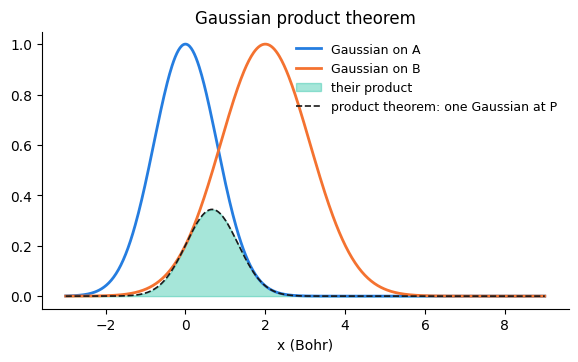

In [4]:
x = np.linspace(-3, 9, 600)
alpha, A, beta, B = 0.8, 0.0, 0.4, 2.0
gA, gB = np.exp(-alpha * (x - A) ** 2), np.exp(-beta * (x - B) ** 2)
P = (alpha * A + beta * B) / (alpha + beta)
predicted = np.exp(-alpha * beta / (alpha + beta) * (A - B) ** 2) * np.exp(-(alpha + beta) * (x - P) ** 2)

fig, ax = plt.subplots(figsize=(6.8, 3.6))
ax.plot(x, gA, color=BLUE, lw=2, label="Gaussian on A")
ax.plot(x, gB, color=ORANGE, lw=2, label="Gaussian on B")
ax.fill_between(x, gA * gB, color=AQUA, alpha=0.35, label="their product")
ax.plot(x, predicted, color=INK, lw=1.2, ls="--", label="product theorem: one Gaussian at P")
ax.set(xlabel="x (Bohr)", title="Gaussian product theorem")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="upper right")
print("largest difference between product and formula:", np.abs(gA * gB - predicted).max())

From here on we take the integrals from a library. PySCF computes them for any angular momentum; the
four arrays below are the complete input to every method that follows.

| Array | Formula | PySCF |
| --- | --- | --- |
| overlap $S_{\mu\nu}$ | $\int\chi_\mu\chi_\nu$ | `mol.intor("int1e_ovlp")` |
| kinetic $T_{\mu\nu}$ | $\int\chi_\mu(-\tfrac12\nabla^2)\chi_\nu$ | `mol.intor("int1e_kin")` |
| nuclear attraction $V_{\mu\nu}$ | $\int\chi_\mu\big(-\sum_A Z_A/|\mathbf r-\mathbf R_A|\big)\chi_\nu$ | `mol.intor("int1e_nuc")` |
| electron repulsion $(\mu\nu|\lambda\sigma)$ | $\iint \chi_\mu(\mathbf r_1)\chi_\nu(\mathbf r_1)\,\frac{1}{r_{12}}\,\chi_\lambda(\mathbf r_2)\chi_\sigma(\mathbf r_2)$ | `mol.intor("int2e")` |

> **Notation warning for physicists.** $(\mu\nu|\lambda\sigma)$ is *chemists' notation*: the first two
> indices belong to electron 1, the last two to electron 2. Physicists' notation is
> $\langle\mu\lambda|\nu\sigma\rangle = (\mu\nu|\lambda\sigma)$. Most index bugs come from mixing the two.

First a check that our hand-written formulas agree with the library, then a real molecule.

In [5]:
# The hydrogen atom of Section 1, now with PySCF integrals for the same three Gaussians.
alphas = even_tempered(3)
h_atom = gto.M(atom="H", spin=1, basis={"H": [[0, [a, 1.0]] for a in alphas]}, verbose=0)
S = h_atom.intor("int1e_ovlp")
H = h_atom.intor("int1e_kin") + h_atom.intor("int1e_nuc")
print("PySCF integrals :", scipy.linalg.eigh(H, S, eigvals_only=True)[0])
print("our formulas    :", hydrogen_in_gaussians(alphas)[0])

PySCF integrals : -0.4923302834706549
our formulas    : -0.49233028347065483


In [6]:
water = gto.M(atom="O 0 0 0; H 0 0.757 0.587; H 0 -0.757 0.587", basis="sto-3g", unit="Angstrom", verbose=0)
print("basis functions:", water.ao_labels())
print("overlap:", water.intor("int1e_ovlp").shape, "  two-electron integrals:", water.intor("int2e").shape)

eri = water.intor("int2e")
print("symmetry (pq|rs) = (qp|rs) = (rs|pq):",
      np.allclose(eri, eri.transpose(1, 0, 2, 3)), np.allclose(eri, eri.transpose(2, 3, 0, 1)))

basis functions: ['0 O 1s    ', '0 O 2s    ', '0 O 2px   ', '0 O 2py   ', '0 O 2pz   ', '1 H 1s    ', '2 H 1s    ']
overlap: (7, 7)   two-electron integrals: (7, 7, 7, 7)
symmetry (pq|rs) = (qp|rs) = (rs|pq): True True


## 3. Hartree–Fock in 15 lines

With several electrons the wavefunction depends on all their coordinates at once. Hartree–Fock makes the
simplest antisymmetric guess, a single Slater determinant: each electron occupies an orbital
$\phi_i = \sum_\mu C_{\mu i}\chi_\mu$ and feels only the *average* field of the others. For a
closed-shell molecule with $N/2$ doubly occupied orbitals, minimising the energy gives

$$\mathbf F\mathbf C = \mathbf S\mathbf C\,\boldsymbol\varepsilon,\qquad
F_{\mu\nu} = h_{\mu\nu} + \sum_{\lambda\sigma} D_{\lambda\sigma}\Big[(\mu\nu|\lambda\sigma) - \tfrac12(\mu\lambda|\nu\sigma)\Big],\qquad
D_{\mu\nu} = 2\sum_i^{\rm occ} C_{\mu i}C_{\nu i}.$$

It is the same generalised eigenvalue problem as in Section 1, except that the matrix $\mathbf F$
depends on its own eigenvectors through the density matrix $\mathbf D$. So we iterate until it stops
changing: the *self-consistent field* (SCF) loop. The two terms in the bracket are the classical Coulomb
repulsion (J) and the exchange term (K) that comes from antisymmetry.

In [7]:
def rhf(mol, D0=None, max_iter=200, tol=1e-9, verbose=True):
    """Restricted Hartree-Fock. Returns total energy, orbital energies, orbital coefficients.

    D0 is an optional starting density matrix; the default starts from no electron repulsion.
    """
    S = mol.intor("int1e_ovlp")
    h = mol.intor("int1e_kin") + mol.intor("int1e_nuc")
    eri = mol.intor("int2e")
    n_occ = mol.nelectron // 2
    D = np.zeros_like(S) if D0 is None else D0
    converged = False
    for iteration in range(1, max_iter + 1):
        J = np.einsum("pqrs,rs->pq", eri, D)
        K = np.einsum("prqs,rs->pq", eri, D)
        F = h + J - 0.5 * K
        orbital_energies, C = scipy.linalg.eigh(F, S)
        D_new = 2 * C[:, :n_occ] @ C[:, :n_occ].T
        if np.abs(D_new - D).max() < tol:
            converged = True
            break
        D = D_new
    energy = 0.5 * np.einsum("pq,pq->", h + F, D) + mol.energy_nuc()
    if verbose or not converged:
        print(f"SCF converged in {iteration} iterations" if converged
              else f"WARNING: SCF not converged after {max_iter} iterations")
    return energy, orbital_energies, C


e_hf, orbital_energies, C = rhf(water)
print(f"our RHF   : {e_hf:.8f} Ha")
print(f"PySCF RHF : {scf.RHF(water).run().e_tot:.8f} Ha")
print("orbital energies:", orbital_energies)

SCF converged in 25 iterations
our RHF   : -74.96306313 Ha
PySCF RHF : -74.96306313 Ha
orbital energies: [-20.24197  -1.26816  -0.61739  -0.45315  -0.39127   0.60514   0.74124]


That is a complete Hartree–Fock program. Production codes add a better starting guess and convergence
acceleration (DIIS), and avoid storing the $n^4$ integrals, but the algorithm is this one. Replacing the
exchange term by a functional of the density turns it into Kohn–Sham DFT.

**The molecular-orbital basis.** Hartree–Fock gives us an orthonormal set of orbitals. Transforming the
integrals to that set,

$$h_{pq} = \sum_{\mu\nu} C_{\mu p}\,h_{\mu\nu}\,C_{\nu q},\qquad
(pq|rs) = \sum_{\mu\nu\lambda\sigma} C_{\mu p}C_{\nu q}\,(\mu\nu|\lambda\sigma)\,C_{\lambda r}C_{\sigma s},$$

gives the many-electron Hamiltonian in second quantisation:

$$\hat H = E_{\rm nuc} + \sum_{pq}\sum_\sigma h_{pq}\,a^\dagger_{p\sigma}a_{q\sigma}
 + \frac12\sum_{pqrs}\sum_{\sigma\tau}(pq|rs)\,a^\dagger_{p\sigma}a^\dagger_{r\tau}a_{s\tau}a_{q\sigma}.$$

This is the object the rest of the school is about. It has the same form as the Hubbard model, with
general $h_{pq}$ instead of a hopping $t$ and a full tensor $(pq|rs)$ instead of a single on-site $U$.

In [8]:
def mo_integrals(mol, C):
    """One- and two-electron integrals in the orbital basis C, and the nuclear repulsion."""
    h = C.T @ (mol.intor("int1e_kin") + mol.intor("int1e_nuc")) @ C
    eri = np.einsum("uvls,up,vq,lr,st->pqrt", mol.intor("int2e"), C, C, C, C, optimize=True)
    return h, eri, mol.energy_nuc()

## 4. Exact diagonalisation in Fock space

Hartree–Fock is one determinant. The exact ground state *within the basis* is a superposition of all of
them, and finding it is a matrix diagonalisation. The most direct way to do it is the one a quantum
computing textbook would use: represent each spin orbital by a qubit (empty or occupied) and each
$a_j$ by a matrix, using the Jordan–Wigner construction

$$a_j = Z\otimes\cdots\otimes Z\otimes \begin{pmatrix}0&1\\0&0\end{pmatrix}\otimes I\otimes\cdots\otimes I ,$$

where the string of $Z$ on the first $j$ qubits supplies the fermionic sign. We do this for four
hydrogen atoms on a square: 4 orbitals, 8 spin orbitals, a $2^8 = 256$ dimensional Fock space.

Square H₄ is a deliberately awkward molecule. By symmetry its two frontier orbitals are degenerate and
there are only two electrons to put in them, so a closed-shell determinant has to pick one of the two.
To make sure everyone lands on the same Hartree–Fock solution we start the SCF from a slightly
rectangular geometry. We come back to what this choice means at the end of the section.

In [9]:
def jordan_wigner_annihilators(n_qubits):
    I, Z = sp.identity(2, format="csr"), sp.diags([1.0, -1.0], format="csr")
    lower = sp.csr_matrix([[0.0, 1.0], [0.0, 0.0]])
    ops = []
    for j in range(n_qubits):
        op = sp.identity(1, format="csr")
        for factor in [Z] * j + [lower] + [I] * (n_qubits - j - 1):
            op = sp.kron(op, factor, format="csr")
        ops.append(op)
    return ops


def fock_space_hamiltonian(h, eri):
    """Second-quantised Hamiltonian as a sparse matrix. Spin orbital (p, sigma) is qubit 2p + sigma."""
    n = h.shape[0]
    a = jordan_wigner_annihilators(2 * n)
    ad = [op.T for op in a]
    H = sp.csr_matrix((4**n, 4**n))
    for p, q in itertools.product(range(n), repeat=2):
        for s in (0, 1):
            H += h[p, q] * ad[2 * p + s] @ a[2 * q + s]
    for p, q, r, t in itertools.product(range(n), repeat=4):
        if abs(eri[p, q, r, t]) < 1e-12:
            continue
        for s1, s2 in itertools.product((0, 1), repeat=2):
            H += 0.5 * eri[p, q, r, t] * ad[2 * p + s1] @ ad[2 * r + s2] @ a[2 * t + s2] @ a[2 * q + s1]
    return H, a


def square_h4(side, stretch=1.0):
    """Four H atoms on a rectangle side x (stretch * side), in Bohr, numbered around the ring."""
    a, b = side, stretch * side
    return gto.M(atom=[["H", (0, 0, 0)], ["H", (a, 0, 0)], ["H", (a, b, 0)], ["H", (0, b, 0)]],
                 basis="sto-3g", unit="Bohr", verbose=0)


def rhf_square_h4(side, verbose=True):
    """RHF for the square, started from the solution of a 2% rectangle."""
    _, _, C0 = rhf(square_h4(side, stretch=1.02), verbose=False)
    return rhf(square_h4(side), D0=2 * C0[:, :2] @ C0[:, :2].T, verbose=verbose)


h4 = square_h4(2.4)
e_hf_h4, _, C_h4 = rhf_square_h4(2.4)
h_mo, eri_mo, e_nuc = mo_integrals(h4, C_h4)

H_fock, a = fock_space_hamiltonian(h_mo, eri_mo)
print("Fock-space Hamiltonian:", H_fock.shape, f"with {H_fock.nnz} non-zero elements")

SCF converged in 2 iterations


Fock-space Hamiltonian: (256, 256) with 2687 non-zero elements


The Hamiltonian conserves the number of up and down electrons, so the matrix is block diagonal. We want
the block with two up and two down electrons.

In [10]:
n_up = sum(a[2 * p].T @ a[2 * p] for p in range(4)).diagonal()
n_dn = sum(a[2 * p + 1].T @ a[2 * p + 1] for p in range(4)).diagonal()
sector = np.where((n_up == 2) & (n_dn == 2))[0]
print(f"states with 2 up and 2 down electrons: {len(sector)} of {H_fock.shape[0]}")

block = H_fock[sector][:, sector].toarray()
e_exact = np.linalg.eigvalsh(block)[0] + e_nuc
e_pyscf = fci.FCI(scf.RHF(h4).run()).kernel()[0]     # FCI does not depend on which RHF solution PySCF finds
print(f"Hartree-Fock           : {e_hf_h4:.8f} Ha")
print(f"exact diagonalisation  : {e_exact:.8f} Ha")
print(f"PySCF FCI              : {e_pyscf:.8f} Ha")
print(f"correlation energy     : {e_exact - e_hf_h4:.6f} Ha")

states with 2 up and 2 down electrons: 36 of 256


Hartree-Fock           : -1.77335273 Ha
exact diagonalisation  : -1.97057462 Ha
PySCF FCI              : -1.97057462 Ha
correlation energy     : -0.197222 Ha


The difference between the exact energy in the basis and the Hartree–Fock energy is *defined* as the
**correlation energy**. It is small compared with the total, and it is where the chemistry is.

In chemistry, exact diagonalisation in a basis is called **full configuration interaction** (FCI).

### Is one determinant enough? Square H₄ in energy and in real space

The correlation energy above is almost 10% of the total energy, far more than for a normal molecule.
To see what is going wrong we compare four levels of theory at this geometry:

- **RHF**: one determinant, up and down electrons share the same orbitals.
- **UHF**: still one determinant, but up and down electrons get their own orbitals. Only a few lines
  differ from `rhf`. We start it from the antiferromagnetic pattern ↑↓↑↓ around the ring.
- **UCCSD(T)**: coupled cluster on top of the UHF determinant (energy only, from PySCF).
- **FCI**: the exact ground state in this basis.

In [11]:
def uhf(mol, Da, Db, max_iter=500, tol=1e-9):
    """Unrestricted Hartree-Fock from starting spin densities Da, Db. Returns energy, Da, Db, <S^2>."""
    S = mol.intor("int1e_ovlp")
    h = mol.intor("int1e_kin") + mol.intor("int1e_nuc")
    eri = mol.intor("int2e")
    n_up, n_dn = mol.nelec
    for iteration in range(max_iter):
        J = np.einsum("pqrs,rs->pq", eri, Da + Db)             # Coulomb: both spins
        Fa = h + J - np.einsum("prqs,rs->pq", eri, Da)         # exchange: same spin only
        Fb = h + J - np.einsum("prqs,rs->pq", eri, Db)
        Ca, Cb = scipy.linalg.eigh(Fa, S)[1], scipy.linalg.eigh(Fb, S)[1]
        Da_new, Db_new = Ca[:, :n_up] @ Ca[:, :n_up].T, Cb[:, :n_dn] @ Cb[:, :n_dn].T
        converged = max(np.abs(Da_new - Da).max(), np.abs(Db_new - Db).max()) < tol
        Da, Db = Da_new, Db_new
        if converged:
            break
    else:
        print("WARNING: UHF not converged")
    energy = 0.5 * (np.einsum("pq,pq->", h + Fa, Da) + np.einsum("pq,pq->", h + Fb, Db)) + mol.energy_nuc()
    s_squared = 0.25 * (n_up - n_dn) * (n_up - n_dn + 2) + n_dn - np.trace(Da @ S @ Db @ S)
    return energy, Da, Db, s_squared


def one_body_density_matrix(psi, a):
    """gamma[p, q] = sum_sigma <psi| a+_{p sigma} a_{q sigma} |psi>."""
    n = len(a) // 2
    return np.array([[sum(psi @ (a[2 * p + s].T @ (a[2 * q + s] @ psi)) for s in (0, 1))
                      for q in range(n)] for p in range(n)])


def solve_square_h4(side):
    """RHF, UHF and exact ground state of square H4. Density matrices are in the atomic-orbital basis."""
    mol = square_h4(side)
    e_rhf, _, C = rhf_square_h4(side, verbose=False)
    neel_up, neel_dn = np.diag([1.0, 0.0, 1.0, 0.0]), np.diag([0.0, 1.0, 0.0, 1.0])
    e_uhf, Da, Db, s_squared = uhf(mol, neel_up, neel_dn)

    h, eri, e_nuc = mo_integrals(mol, C)
    H, a = fock_space_hamiltonian(h, eri)
    energies, vectors = np.linalg.eigh(H[sector][:, sector].toarray())
    psi = np.zeros(H.shape[0])
    psi[sector] = vectors[:, 0]                              # exact ground state in the full Fock space
    gamma = one_body_density_matrix(psi, a)                  # in the RHF orbital basis
    return dict(mol=mol, side=side, e_rhf=e_rhf, e_uhf=e_uhf, e_fci=energies[0] + e_nuc,
                s_squared=s_squared, occupations=np.linalg.eigvalsh(gamma)[::-1],
                D_rhf=2 * C[:, :2] @ C[:, :2].T, D_uhf=Da + Db, D_spin=Da - Db, D_fci=C @ gamma @ C.T)


state = solve_square_h4(2.4)
e_four_atoms = 4 * scf.UHF(gto.M(atom="H", spin=1, basis="sto-3g", verbose=0)).run().e_tot

# Coupled cluster on top of the UHF determinant, from PySCF (the method is introduced in Section 6).
mol = state["mol"]
neel = (np.diag([1.0, 0.0, 1.0, 0.0]), np.diag([0.0, 1.0, 0.0, 1.0]))
mf_uhf = scf.UHF(mol)
mf_uhf.kernel(dm0=neel)                                   # same solution as our own uhf()
ucc = cc.UCCSD(mf_uhf).run()
e_uccsd_t = ucc.e_tot + ucc.ccsd_t()

print("Square H4, side 2.4 Bohr, STO-3G")
print(f"{'':16s} {'energy (Ha)':>12s} {'error (Ha)':>11s} {'error (eV)':>11s} {'<S^2>':>7s}")
for label, e, s2 in [("RHF", state["e_rhf"], "0.00"), ("UHF", state["e_uhf"], f"{state['s_squared']:.2f}"),
                     ("UCCSD(T) on UHF", e_uccsd_t, "-"), ("exact (FCI)", state["e_fci"], "0.00")]:
    error = e - state["e_fci"]
    print(f"{label:16s} {e:12.5f} {error:11.5f} {error * 27.2114:11.2f} {s2:>7s}")
print(f"{'4 separate H':16s} {e_four_atoms:12.5f}")
print("\nexact natural occupations:", np.round(state["occupations"], 2), "  (RHF: [2. 2. 0. 0.])")

Square H4, side 2.4 Bohr, STO-3G
                  energy (Ha)  error (Ha)  error (eV)   <S^2>
RHF                  -1.77335     0.19722        5.37    0.00
UHF                  -1.93369     0.03689        1.00    1.20
UCCSD(T) on UHF      -1.96207     0.00850        0.23       -
exact (FCI)          -1.97057     0.00000        0.00    0.00
4 separate H         -1.86633

exact natural occupations: [1.9 1.  1.  0.1]   (RHF: [2. 2. 0. 0.])


**Energies.** RHF is wrong by 0.20 Ha (5.4 eV), and it even lies above four separate hydrogen atoms: at
this level the molecule is not bound at all. UHF is far better, 0.04 Ha from the exact answer.

So is UHF a single determinant that works? The other numbers say no. The exact ground state is a
singlet, $\langle S^2\rangle = 0$, whereas the UHF determinant has $\langle S^2\rangle = 1.2$: it is a
mixture of singlet, triplet and higher spin states. And in the exact state the two middle natural
occupations are exactly 1: two electrons spread evenly over two degenerate orbitals. A closed-shell
determinant can only give 2, 2, 0, 0.

The third row is the standard remedy for the shortcomings of one determinant: coupled cluster with
single, double and perturbative triple excitations, built on the UHF determinant. For ordinary
molecules it is accurate to about 0.001 Ha (Section 6). Here it recovers three quarters of the
remaining error and still misses 0.009 Ha (0.23 eV, about 5 kcal/mol). A poor starting determinant
limits even a very good correction.

**Real space.** Now plot the electron density
$\rho(\mathbf r) = \sum_{\mu\nu} D_{\mu\nu}\,\chi_\mu(\mathbf r)\chi_\nu(\mathbf r)$ in the plane of the
molecule for the three wavefunctions.

side 2.4 Bohr: RHF error 0.1972 Ha, UHF error 0.0369 Ha, UHF <S^2> = 1.20


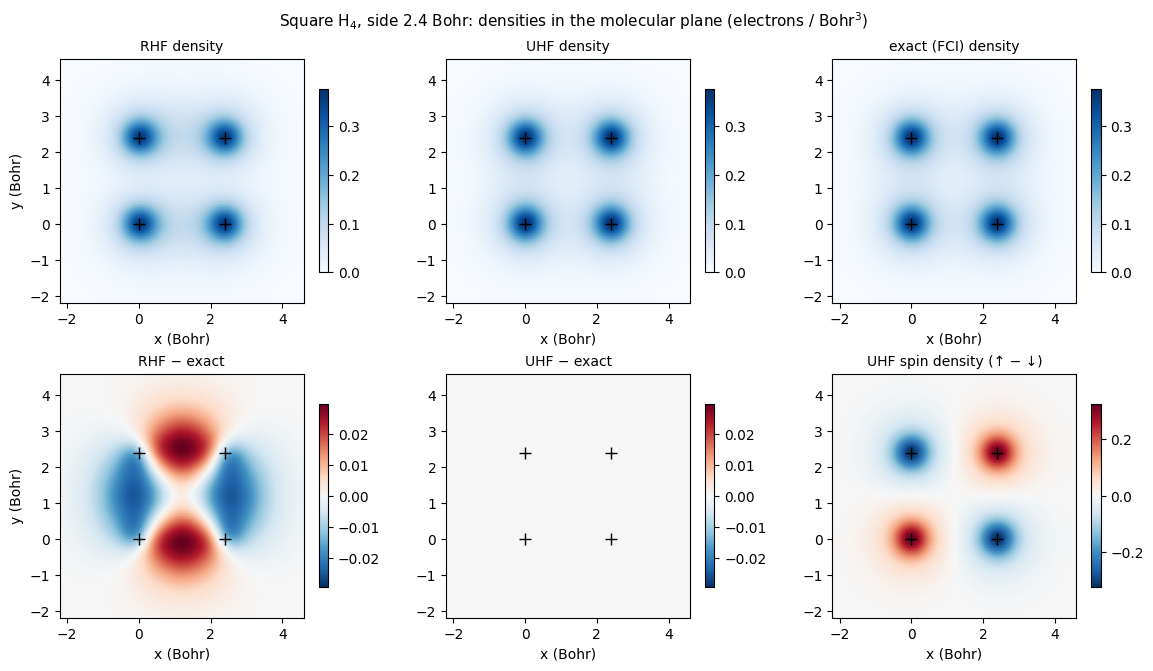

In [12]:
def density_in_plane(mol, D, x, y):
    X, Y = np.meshgrid(x, y)
    coords = np.column_stack([X.ravel(), Y.ravel(), np.zeros(X.size)])
    chi = mol.eval_gto("GTOval", coords)                     # atomic orbitals on the grid
    return np.einsum("gp,pq,gq->g", chi, D, chi).reshape(X.shape)


side = state["side"]
x = y = np.linspace(-2.2, side + 2.2, 161)
rho = {name: density_in_plane(state["mol"], state["D_" + name], x, y) for name in ["rhf", "uhf", "fci", "spin"]}
corners = state["mol"].atom_coords()
extent = [x[0], x[-1], y[0], y[-1]]

fig, axes = plt.subplots(2, 3, figsize=(11.5, 6.6), constrained_layout=True)
top = [("rhf", "RHF density"), ("uhf", "UHF density"), ("fci", "exact (FCI) density")]
for ax, (name, title) in zip(axes[0], top):
    im = ax.imshow(rho[name], origin="lower", extent=extent, cmap="Blues", vmin=0, vmax=rho["fci"].max())
    ax.set_title(title, fontsize=10)
    fig.colorbar(im, ax=ax, shrink=0.75)

limit = np.abs(rho["rhf"] - rho["fci"]).max()
bottom = [(rho["rhf"] - rho["fci"], "RHF − exact"), (rho["uhf"] - rho["fci"], "UHF − exact"),
          (rho["spin"], "UHF spin density (↑ − ↓)")]
for ax, (values, title) in zip(axes[1], bottom):
    vmax = np.abs(values).max() if "spin" in title else limit     # the two differences share a scale
    im = ax.imshow(values, origin="lower", extent=extent, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_title(title, fontsize=10)
    fig.colorbar(im, ax=ax, shrink=0.75)
for ax in axes.ravel():
    ax.plot(corners[:, 0], corners[:, 1], "k+", ms=9)        # nuclei
    ax.set_xlabel("x (Bohr)")
axes[0, 0].set_ylabel("y (Bohr)")
axes[1, 0].set_ylabel("y (Bohr)")
fig.suptitle("Square H$_4$, side 2.4 Bohr: densities in the molecular plane (electrons / Bohr$^3$)", fontsize=11)

print(f"side {side} Bohr: RHF error {state['e_rhf'] - state['e_fci']:.4f} Ha, "
      f"UHF error {state['e_uhf'] - state['e_fci']:.4f} Ha, UHF <S^2> = {state['s_squared']:.2f}")

**What to notice.**

- **RHF breaks the shape of the molecule.** The exact density has the full symmetry of the square. The
  RHF density does not: it piles charge onto two opposite edges and depletes the other two, as if the
  square were two H₂ molecules side by side. Occupying the *other* degenerate orbital would give the same
  picture rotated by 90°. The exact state is an equal superposition of the two.
- **UHF repairs the density by breaking the spin.** Its total density cannot be told apart from the
  exact one on this scale. The price is the bottom right panel: up electrons on two corners, down
  electrons on the other two. The exact singlet has zero spin density everywhere. UHF has replaced a quantum superposition by a classical
  antiferromagnet.
### Is there a better single determinant?

Hartree–Fock equations have many solutions, and an SCF loop only finds the one nearest to its starting
point. Before blaming the method we should check that we have its best answer. PySCF can test whether
a solution is a true minimum (a *stability analysis*), both among UHF determinants and among fully
general ones in which each orbital may mix up and down spin (GHF). We also try a set of random starting
points, and the determinant with three up and one down electron.

In [13]:
_, _, stable_uhf, stable_ghf = mf_uhf.stability(external=True, return_status=True)
print(f"PySCF UHF from the antiferromagnetic start: {mf_uhf.e_tot:.5f} Ha  (ours: {state['e_uhf']:.5f})")
print(f"  minimum among UHF determinants: {stable_uhf};  among general (GHF) determinants: {stable_ghf}")

rng = np.random.default_rng(0)
found = set()
for trial in range(30):                                   # random pairs of occupied orbitals per spin
    Qa, Qb = (np.linalg.qr(rng.normal(size=(4, 4)))[0][:, :2] for _ in range(2))
    mf_trial = scf.UHF(mol)
    mf_trial.kernel(dm0=(Qa @ Qa.T, Qb @ Qb.T))
    found.add(round(float(mf_trial.e_tot), 4))
print("UHF energies reached from 30 random starts:", sorted(found))

mol_triplet = gto.M(atom=mol.atom, basis="sto-3g", unit="Bohr", spin=2, verbose=0)
mf_triplet = scf.UHF(mol_triplet).run()
print(f"UHF with 3 up, 1 down electrons: {mf_triplet.e_tot:.5f} Ha")
print(f"exact (FCI)                    : {state['e_fci']:.5f} Ha")

PySCF UHF from the antiferromagnetic start: -1.93369 Ha  (ours: -1.93369)
  minimum among UHF determinants: True;  among general (GHF) determinants: True


UHF energies reached from 30 random starts: [-1.9337, -1.8008, -1.7859]
UHF with 3 up, 1 down electrons: -1.87446 Ha
exact (FCI)                    : -1.97057 Ha


The antiferromagnetic UHF solution is the best there is: it is a minimum even when the orbitals are
allowed to mix spins, no random start finds anything lower, and the high-spin determinant is higher
still. The remaining 0.04 Ha (1 eV) cannot be recovered by *any* single determinant.

- **Neither determinant is the ground state.** Each one gets some observables right by getting a
  symmetry wrong. This is the signature of **strong** (or static) correlation: the wavefunction needs
  at least two determinants of equal weight before any small corrections are added.

Physicists will recognise the four-site Hubbard ring at half filling, with RHF as the band picture and
UHF as the Néel mean-field state. Most molecules near their equilibrium geometry are not like this, and
for them one determinant is an excellent starting point (Section 6).

## 5. Full CI for larger systems: never build the matrix

The approach of Section 4 stops working almost immediately. The Fock space has $4^n$ states; even the
correct particle-number sector has $\binom{n}{N_\uparrow}\binom{n}{N_\downarrow}$ of them, and the
matrix has that number squared of entries. Three ideas from the 1980s make FCI practical up to about
$10^{10}$ determinants.

**1. Store the wavefunction as a matrix.** A determinant is a choice of occupied up orbitals (an
"α string") and of occupied down orbitals (a "β string"). So the wavefunction is a matrix
$C_{I_\alpha I_\beta}$, not a long vector.

**2. Write $\hat H$ with spin-summed excitation operators** $\hat E_{pq} = \sum_\sigma a^\dagger_{p\sigma}a_{q\sigma}$:

$$\hat H = \sum_{pq} k_{pq}\,\hat E_{pq} + \frac12\sum_{pqrs}(pq|rs)\,\hat E_{pq}\hat E_{rs},
\qquad k_{pq} = h_{pq} - \frac12\sum_r (pr|rq).$$

Each $\hat E_{pq}$ acts on the α string or on the β string, never both, so all we need is a small table
of how single excitations act on strings.

**3. Only ever compute $\sigma = \hat H C$.** Iterative eigensolvers (Lanczos, Davidson) need nothing
else. The Hamiltonian matrix is never stored.

In [14]:
def make_strings(n_orb, n_elec):
    """All occupation strings of n_elec electrons in n_orb orbitals, as bit masks."""
    return [sum(1 << i for i in occ) for occ in itertools.combinations(range(n_orb), n_elec)]


def excitation_table(n_orb, n_elec):
    """E[p, q, I, J] = <string I| a+_p a_q |string J>, including the fermionic sign."""
    strings = make_strings(n_orb, n_elec)
    index = {s: i for i, s in enumerate(strings)}
    E = np.zeros((n_orb, n_orb, len(strings), len(strings)))
    for J, s in enumerate(strings):
        for q in range(n_orb):
            if not s >> q & 1:
                continue
            removed = s ^ (1 << q)
            for p in range(n_orb):
                if removed >> p & 1:
                    continue
                lo, hi = min(p, q), max(p, q)
                between = bin(removed >> (lo + 1) & ((1 << (hi - lo - 1)) - 1)).count("1") if hi > lo else 0
                E[p, q, index[removed | (1 << p)], J] = (-1) ** between
    return E


def fci_by_hand(h, eri, n_orb, n_alpha, n_beta):
    """Ground-state energy (without nuclear repulsion) by direct CI."""
    Ea, Eb = excitation_table(n_orb, n_alpha), excitation_table(n_orb, n_beta)
    k = h - 0.5 * np.einsum("prrq->pq", eri)
    shape = (Ea.shape[2], Eb.shape[2])

    EbT = Eb.transpose(0, 1, 3, 2)

    def sigma(c):
        C = c.reshape(shape)
        # D[p, q] = E_pq |C>: E acts on the alpha strings (rows) or on the beta strings (columns)
        D = Ea @ C + C @ EbT
        G = 0.5 * np.tensordot(eri, D, axes=2)            # G[p, q] = 1/2 sum_rs (pq|rs) D[r, s]
        HC = np.tensordot(k, D, axes=2)                   # one-body part
        HC += (Ea @ G + G @ EbT).sum(axis=(0, 1))         # sum_pq E_pq |G[p, q]>
        return HC.ravel()

    dim = shape[0] * shape[1]
    operator = scipy.sparse.linalg.LinearOperator((dim, dim), matvec=sigma, dtype=float)
    guess = np.zeros(dim)
    guess[0] = 1.0                                   # the Hartree-Fock determinant
    energy, vector = scipy.sparse.linalg.eigsh(operator, k=1, which="SA", v0=guess)
    return energy[0], vector[:, 0].reshape(shape)


e_fci_h4, _ = fci_by_hand(h_mo, eri_mo, 4, 2, 2)
print(f"H4, direct CI by hand       : {e_fci_h4 + e_nuc:.8f} Ha")
print(f"H4, Fock-space diagonalisation: {e_exact:.8f} Ha")

H4, direct CI by hand       : -1.97057462 Ha
H4, Fock-space diagonalisation: -1.97057462 Ha


The same routine now handles molecules far beyond the reach of Section 4.

In [15]:
def run_fci_by_hand(mol):
    e_hf, _, C = rhf(mol)
    h, eri, e_nuc = mo_integrals(mol, C)
    n = mol.nao
    t0 = time.time()
    e, _ = fci_by_hand(h, eri, n, *mol.nelec)
    return e_hf, e + e_nuc, comb(n, mol.nelec[0]) * comb(n, mol.nelec[1]), time.time() - t0


lih = gto.M(atom="Li 0 0 0; H 0 0 1.595", basis="6-31g", unit="Angstrom", verbose=0)
for name, mol in [("H2O/STO-3G", water), ("LiH/6-31G", lih)]:
    e_hf, e_ours, dim, seconds = run_fci_by_hand(mol)
    e_ref = fci.FCI(scf.RHF(mol).run()).kernel()[0]
    print(f"{name}: {dim:5d} determinants, {4**mol.nao:.0e} Fock states | "
          f"ours {e_ours:.8f}  PySCF {e_ref:.8f}  ({seconds:.1f} s)\n")

SCF converged in 25 iterations


H2O/STO-3G:   441 determinants, 2e+04 Fock states | ours -75.01264712  PySCF -75.01264712  (0.1 s)

SCF converged in 26 iterations


LiH/6-31G:  3025 determinants, 4e+06 Fock states | ours -7.99827613  PySCF -7.99827613  (2.7 s)



PySCF's FCI is this algorithm with the loops in C, with the excitation table stored sparsely and with
spatial and spin symmetry. It reaches a few million determinants in seconds on a laptop:

In [16]:
water_631g = gto.M(atom="O 0 0 0; H 0 0.757 0.587; H 0 -0.757 0.587", basis="6-31g", unit="Angstrom", verbose=0)
mf = scf.RHF(water_631g).run()
t0 = time.time()
e_fci = fci.FCI(mf).kernel()[0]
print(f"H2O/6-31G: {comb(13, 5)**2:,} determinants, FCI = {e_fci:.8f} Ha in {time.time() - t0:.1f} s")

H2O/6-31G: 1,656,369 determinants, FCI = -76.12086754 Ha in 6.2 s


And then it stops, because the dimension grows combinatorially with both the number of electrons and the
size of the basis.

In [17]:
print(f"{'system':28s} {'orbitals':>8s} {'electrons':>9s} {'determinants':>13s}")
for name, n, (na, nb) in [("H4 / STO-3G", 4, (2, 2)), ("H2O / STO-3G", 7, (5, 5)), ("LiH / 6-31G", 11, (2, 2)),
                          ("H2O / 6-31G", 13, (5, 5)), ("H2O / cc-pVDZ", 24, (5, 5)),
                          ("N2 / cc-pVDZ", 28, (7, 7)), ("benzene / cc-pVDZ", 114, (21, 21)),
                          ("Cr2 / cc-pVDZ-DK", 86, (24, 24))]:
    print(f"{name:28s} {n:8d} {na + nb:9d} {float(comb(n, na) * comb(n, nb)):13.1e}")

system                       orbitals electrons  determinants
H4 / STO-3G                         4         4       3.6e+01
H2O / STO-3G                        7        10       4.4e+02
LiH / 6-31G                        11         4       3.0e+03
H2O / 6-31G                        13        10       1.7e+06
H2O / cc-pVDZ                      24        10       1.8e+09
N2 / cc-pVDZ                       28        14       1.4e+12
benzene / cc-pVDZ                 114        42       1.9e+45
Cr2 / cc-pVDZ-DK                   86        48       1.5e+42


The largest FCI calculations ever done hold about $10^{12}$ determinants. Water in a modest basis is
already out of reach.

## 6. Everything else is an approximation to Section 5

Every method in the rest of this school is a way of getting close to the FCI answer without paying the
FCI price. They all start from the arrays you have just built.

| Method | Idea | Cost |
| --- | --- | --- |
| Hartree–Fock, DFT | one determinant | $N^3$–$N^4$ |
| MP2 | second-order perturbation theory around Hartree–Fock | $N^5$ |
| CCSD, CCSD(T) | exponential of single and double excitations | $N^6$, $N^7$ |
| CASSCF | FCI in a few chosen orbitals, mean field for the rest | exponential in the active space |
| DMRG, tensor networks | FCI vector compressed as a matrix product state | polynomial for a fixed bond dimension |
| AFQMC | FCI vector sampled stochastically | $N^3$–$N^4$ per sample |

As an example of how short they can be, here is MP2. In the Hartree–Fock orbital basis the first-order
wavefunction is a sum of double excitations $i,j\to a,b$ with amplitudes
$t_{ij}^{ab} = (ia|jb)/(\varepsilon_i+\varepsilon_j-\varepsilon_a-\varepsilon_b)$, and

$$E_{\rm MP2} = \sum_{ijab} t_{ij}^{ab}\,\big[2(ia|jb) - (ib|ja)\big].$$

In [18]:
def mp2_by_hand(mol):
    e_hf, eps, C = rhf(mol)
    _, eri, _ = mo_integrals(mol, C)
    o, v = slice(0, mol.nelectron // 2), slice(mol.nelectron // 2, None)
    ovov = eri[o, v, o, v]
    t = ovov / (eps[o, None, None, None] - eps[None, v, None, None] + eps[None, None, o, None] - eps[None, None, None, v])
    return e_hf, np.einsum("iajb,iajb->", t, 2 * ovov - ovov.transpose(0, 3, 2, 1))


e_hf, e_mp2 = mp2_by_hand(water_631g)
print(f"MP2 correlation energy, ours : {e_mp2:.8f} Ha")
print(f"MP2 correlation energy, PySCF: {mp.MP2(mf).run().e_corr:.8f} Ha")

SCF converged in 45 iterations
MP2 correlation energy, ours : -0.12886859 Ha
MP2 correlation energy, PySCF: -0.12886860 Ha


In [19]:
# How much of the exact correlation energy does each method recover for H2O/6-31G?
mycc = cc.CCSD(mf).run()
e_corr = {"MP2": e_mp2, "CCSD": mycc.e_corr, "CCSD(T)": mycc.e_corr + mycc.ccsd_t(), "FCI": e_fci - mf.e_tot}
print(f"Hartree-Fock energy: {mf.e_tot:.6f} Ha")
for name, e in e_corr.items():
    print(f"  {name:8s} correlation energy {e:.6f} Ha   {100 * e / e_corr['FCI']:6.2f}% of exact   "
          f"error {abs(e - e_corr['FCI']) * 627.5:6.2f} kcal/mol")

Hartree-Fock energy: -75.983948 Ha
  MP2      correlation energy -0.128869 Ha    94.12% of exact   error   5.05 kcal/mol
  CCSD     correlation energy -0.135398 Ha    98.89% of exact   error   0.95 kcal/mol
  CCSD(T)  correlation energy -0.136394 Ha    99.62% of exact   error   0.33 kcal/mol
  FCI      correlation energy -0.136919 Ha   100.00% of exact   error   0.00 kcal/mol


For water near its equilibrium geometry the hierarchy converges fast: CCSD(T) is within a fraction of
a kcal/mol of the exact answer at a tiny fraction of the cost. That is the normal situation in
chemistry. The next notebook is about a molecule where it is not.

## What you now have

- A molecule and a basis set define four arrays: $S$, $T$, $V$ and $(\mu\nu|\lambda\sigma)$.
- Hartree–Fock is a generalised eigenvalue problem solved to self-consistency.
- Its orbitals give the second-quantised Hamiltonian $h_{pq}$, $(pq|rs)$.
- FCI diagonalises that Hamiltonian exactly, using only the action $\sigma = \hat H C$.
- Every other method is `einsum` on the same arrays.

## Exercises

1. **Basis-set convergence.** In Section 1, change `ratio` and `centre` in `even_tempered`. How few
   Gaussians can reach an error of $10^{-4}$ Ha? Why does the error from the cusp decay slowly?
2. **Change the size.** Repeat the comparison of Section 4 for squares of side 1.6 to 4.0 Bohr and plot
   the three energies. Which of RHF and UHF goes to the right limit of four separate atoms? What
   happens to the UHF $\langle S^2\rangle$?
3. **From rectangle to square.** `square_h4(side, stretch)` builds a rectangle. Follow the RHF error, the
   UHF $\langle S^2\rangle$ and the natural occupations as `stretch` goes from 2.0 (two separate H₂
   molecules) to 1.0. Where does one determinant stop being enough?
4. **Hubbard model.** `fock_space_hamiltonian` takes any `h` and `eri`. Build a 4-site Hubbard chain
   (`h[i, i+1] = h[i+1, i] = -t`, `eri[i, i, i, i] = U`) and find its ground-state energy at half
   filling for $U/t = 0, 4, 8$.
5. **Density matrix.** From the FCI matrix `C` returned by `fci_by_hand` and the excitation tables,
   compute the one-particle density matrix $\gamma_{pq} = \langle\hat E_{pq}\rangle$ and diagonalise
   it. How far are the natural occupations from 2 and 0 for water? For stretched H₄?
6. **Truncated CI.** Restrict the FCI vector to determinants that differ from Hartree–Fock by at most
   two excitations (CISD). How much correlation energy is lost for water, and for two water molecules
   far apart?
7. **The other RHF solutions.** Call `rhf(square_h4(2.4))` without a starting density, and compare
   with `rhf_square_h4(2.4)` and with PySCF. How many different RHF energies can you find, and what do
   their densities look like?
8. **Coupled cluster.** Using the MP2 amplitudes as a starting guess, implement the CCD equations from
   a textbook and compare with `cc.CCSD`.